In [1]:
# HYPOTHESIS TESTING

import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
insurance_df = pd.read_csv('insurance.csv')

insurance_df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [3]:
sns.set_palette('bright')
sns.set_style('darkgrid')

<Axes: xlabel='bmi', ylabel='charges'>

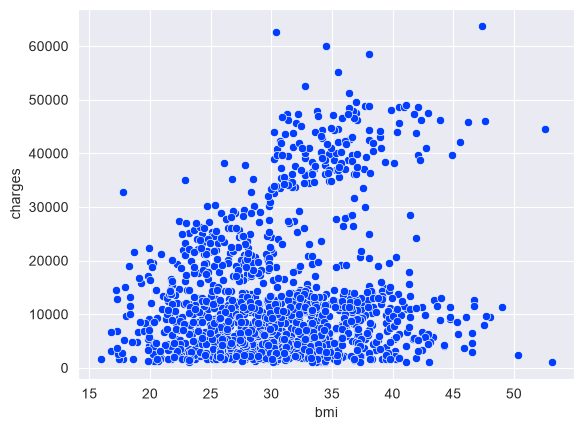

In [4]:
sns.scatterplot(data=insurance_df, x ='bmi', y='charges')

In [7]:
# Is there a statistical significant relationship 
# between bmi and charges

# Set the hypotheses
null = 'There is no significant relationship between bmi and charges'
alternative = 'There is a significant relationship between bmi and charges'

# Choose the level of significance
alpha = 0.05

# Compute the test
correlation_coeff, pvalue = stats.spearmanr(insurance_df['bmi'], insurance_df['charges'])

# Decision rule
if pvalue < alpha:
    print(f'{alternative} @ pvalue of {pvalue:.6f}')
else:
    print(f'{null} @ pvalue of {pvalue:.6f}')

There is a significant relationship between bmi and charges @ pvalue of 0.000012


In [10]:
# Is there statistical significan relationship between region and smoking habit

# Set the hypotheses
null = 'There is no significant relationship between region and smoking habit'
alternative = 'There is a significant relationship between region and smoking habit'

# Choose the level of significance
alpha = 0.05

# Compute the test
chi_data = pd.crosstab(insurance_df['region'], insurance_df['smoker'])
chi_stats, pvalue, dof, exp = stats.chi2_contingency(chi_data)
# Decision rule
if pvalue < alpha:
    print(f'{alternative} @ pvalue of {round(pvalue, 4)}')
else:
    print(f'{null} @ pvalue of {round(pvalue, 4)}')

There is no significant relationship between region and smoking habit @ pvalue of 0.0617


<Axes: xlabel='sex', ylabel='charges'>

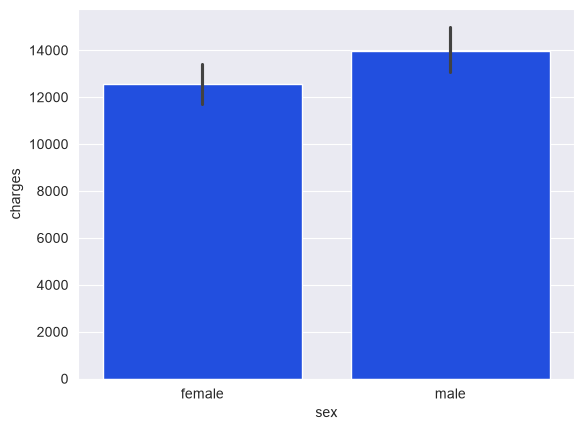

In [11]:
sns.barplot(data=insurance_df, x ='sex', y = 'charges')

In [12]:
# is there a statistical significant difference between charges across gender

# Set the hypotheses
null = 'There is no significant difference between charges across gender'
alternative = 'There is a significant difference between charges across gender'

# Choose the level of significance
alpha = 0.05

# Compute the test
male_charges = insurance_df[insurance_df['sex']== 'male']['charges'].values
female_charges = insurance_df[insurance_df['sex']== 'female']['charges'].values

t_stats, pvalue = stats.ttest_ind(male_charges, female_charges)

# Decision rule
if pvalue < alpha:
    print(f'{alternative} @ pvalue of {round(pvalue, 4)}')
else:
    print(f'{null} @ pvalue of {round(pvalue, 4)}')

There is a significant difference between charges across gender @ pvalue of 0.0361
